In [1]:
%matplotlib widget
import importlib
import numpy as np
import scipy as sc
from mpl_toolkits.mplot3d import Axes3D
import os
import matplotlib.pyplot as plt
import time

#Mes imports

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\Extinction_changes')
import nano_objects
importlib.reload(nano_objects)
from nano_objects import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\Permittivity changes estimation')
from Permittivity_change_func import *
import Permittivity_change_func
importlib.reload(Permittivity_change_func)
from Permittivity_change_func  import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\Extinction_changes')
from Optical_amplitude_estimation_func import *
import Optical_amplitude_estimation_func
importlib.reload(Optical_amplitude_estimation_func)
from Optical_amplitude_estimation_func  import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\PaP_calculate_quantitative_signal')
import PaP_quantitative_study_func
importlib.reload(PaP_quantitative_study_func)
from PaP_quantitative_study_func import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\PaP_calculate_quantitative_signal')
import PaP_quantitative_study_plot
importlib.reload(PaP_quantitative_study_plot)
from PaP_quantitative_study_plot import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Traces_treatment')
import P_and_P_func
importlib.reload(P_and_P_func)
from P_and_P_func import *


# Get exp data

In [4]:
ND_names = ['Membrane 3,5 - ND3,5-5', 'Sapphire 2,3 - NDd zone 3', 'Silice thick 4,5 - D1 zone1', 'Silice thick 4,5 - D2 zone1']
ND_names = ['Sapphire 2,3 - NDd zone 3', 'Silice thick 4,5 - D1 zone1', 'Silice thick 4,5 - D2 zone1']

Colors = {}

Colors['Membrane 3,5 - ND3,5-5'] = ["#ffa826"]
Colors['Sapphire 2,3 - NDd zone 3'] = ["#0073c6"]
Colors['Silice thick 4,5 - D1 zone1'] = ["#9e00ba"]
Colors['Silice thick 4,5 - D2 zone1'] = ["#000294"]


Lda_SPR = {}
Lda_SPR['Membrane 3,5 - ND3,5-5'] =  599e-9
Lda_SPR['Sapphire 2,3 - NDd zone 3'] = 638e-9
Lda_SPR['Silice thick 4,5 - D1 zone1'] = 624e-9
Lda_SPR['Silice thick 4,5 - D2 zone1'] = 631e-9

In [5]:
Exp_data={}

dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study'
for name in ND_names:
    Exp_data[name] = get_treated_experimental_data(r'\\'.join([dir_root, name]), lda_SPR = Lda_SPR[name], color = Colors[name][0]) 



## Get COMSOL spectra data
Linear spectra ans plasmonic derivative obtained from COMSOL simulations

In [ ]:
dir_root = r'H:\commun\Utilisateur FNO\Nathan\COMSOL\AuND\Optical detection\SPR'
COMSOL_spectra = {}

spectra_name_root = 'SPR - fixed mesh'


for name in ND_names:
    COMSOL_spectra[name] = get_COMSOL_spectra_with_deps1_deps2(r'\\'.join([dir_root, name]), lda_SPR = Lda_SPR[name], color = Colors[name][0]) 

# ND_name_3 = r'Membrane 3,5 - ND3,5-5'
# spectra_name_root_3 = r'COMSOL - AR3.5-5 - linear spectra - gamma_surf_116_meV'
# COMSOL_spectra['Membrane 3,5 - ND3,5-5'] = get_COMSOL_spectra_with_deps1_deps2(dir_root, ND_name_3, spectra_name_root_3)

ND_name_3 = r'Sapphire 2,3 - NDd zone 3'
spectra_name_root_3 = r'COMSOL - Sapphire 2,3 - NDd zone 3 - linear spectra - gamma_surf_22_meV'
COMSOL_spectra['Sapphire 2,3 - NDd zone 3'] = get_COMSOL_spectra_with_deps1_deps2(dir_root, ND_name_3, spectra_name_root_3)

ND_name_3 = r'Silice thick 4,5 - D1 zone1'
spectra_name_root_3 = r'COMSOL - Silice thick 4,5 - D1 zone1 - linear spectra - gamma_surf_19_meV'
COMSOL_spectra['Silice thick 4,5 - D1 zone1'] = get_COMSOL_spectra_with_deps1_deps2(dir_root, ND_name_3, spectra_name_root_3)

ND_name_3 = r'Silice thick 4,5 - D2 zone1'
spectra_name_root_3 = r'COMSOL - Silice thick 4,5 - D2 zone1 - linear spectra -  D=109,4nm - e=23.5nm - gamma_surf_0_meV'
COMSOL_spectra['Silice thick 4,5 - D2 zone1'] = get_COMSOL_spectra_with_deps1_deps2(dir_root, ND_name_3, spectra_name_root_3)

In [5]:
Permittivity_change = {}

Energy = np.linspace(1.1, 3.9, 1000)
alpha = 1.42e-5 #in K-1

#Gold values from Stoll 2014
w_p = 9.01 * sc.constants.e / sc.constants.hbar
gamma_0 = 67*1e-3 * sc.constants.e / sc.constants.hbar
dgamma_dT = 0.125e-3 * sc.constants.e / sc.constants.hbar #eV/K e-ph scattering change 


## Compute permittivity changes

In [6]:
#Ib contribution
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Interband sensitivity model\Computed interband changes'
fname = 'Interband contribution - Stoll fit - with Stoll coefficients.csv'
Permittivity_change['ib'] = get_treated_interband_contribution(dir_root, fname)

# Raw data from stoll 2014
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Acoustic model - data'
Permittivity_change['Stoll ib'] = get_interband_contribution_Stoll_2014(dir_root)


# e density
delta_eps1_func, delta_eps2_func = Delta_eps_e_density(w_p = w_p, gamma_0 = gamma_0)
Permittivity_change['Drude'] = {}
Permittivity_change['Drude']['e density'] = {}
Permittivity_change['Drude']['e density']['delta_eps1'] = delta_eps1_func
Permittivity_change['Drude']['e density']['delta_eps2'] = delta_eps2_func


# e-ph scattering
deps1_dT_scattering, deps2_dT_scattering = Delta_eps_e_ph_scattering(w_p, gamma_0, dgamma_dT)

Permittivity_change['Drude']['e-ph scattering'] = {}
Permittivity_change['Drude']['e-ph scattering']['delta_eps1'] = deps1_dT_scattering
Permittivity_change['Drude']['e-ph scattering']['delta_eps2'] = deps2_dT_scattering

## Get Stoll and Cahill table of permittivity change with T for comparison 

In [7]:
# Raw data from stoll 2014
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Acoustic model - data'
Permittivity_change['Stoll'] = get_deps_dT_Stoll_2014(dir_root)


root_cahill = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Acoustic model - data'
fname_cahill = 'Cahill_eps_variations_dT.csv'
Permittivity_change['Cahill'] = get_Cahill_data(root_cahill, fname_cahill)

## Compute the thermal amplitude

In [8]:
Ds = {}
for key in ND_names :
    Ds[key] = {}

In [14]:
for key in ND_names :

    #Ds[key]['mine'] = compute_heating_changes(Permittivity_change, COMSOL_spectra[key], band_contribution='Ldp', with_dilatation=False)
    Ds[key]['mine'] = compute_heating_changes(Permittivity_change, COMSOL_spectra[key], band_contribution='nothing', with_dilatation=False)
    Ds[key]['Cahill'] = compute_heating_changes_Cahill(Permittivity_change, COMSOL_spectra[key], with_dilatation=False)
    Ds[key]['Stoll'] = compute_heating_changes_Stoll(Permittivity_change, COMSOL_spectra[key], with_dilatation=False)

    dir_root_save_data = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study'
    dir_to_save = '\\'.join((dir_root_save_data, key, r'Extinction variation calculation\Thermal model'))
    save_data = 1
    if save_data :
        save_ext_change_data_excel(key + ' - Extinction change - heating - Cahill table', dir_to_save, Ds[key]['Cahill'])
        save_ext_change_data_excel(key + ' - Extinction change - heating - Stoll table', dir_to_save, Ds[key]['Stoll'])
        save_ext_change_data_excel(key + ' - Extinction change - heating - Drude only table', dir_to_save, Ds[key]['mine'])

In [10]:
# for key in ND_names :
#     fig, ax = plt.subplots(figsize = (6, 6))
#     ax.plot(1240/COMSOL_spectra[key]['energy'], -Permittivity_change['ib']['deps1/deV']['Ldp'](COMSOL_spectra[key]['energy']) * -1.7e-4, color="#000000",)

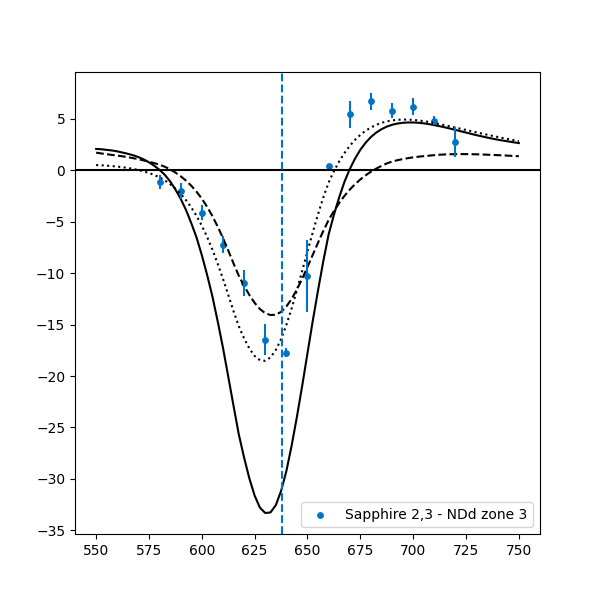

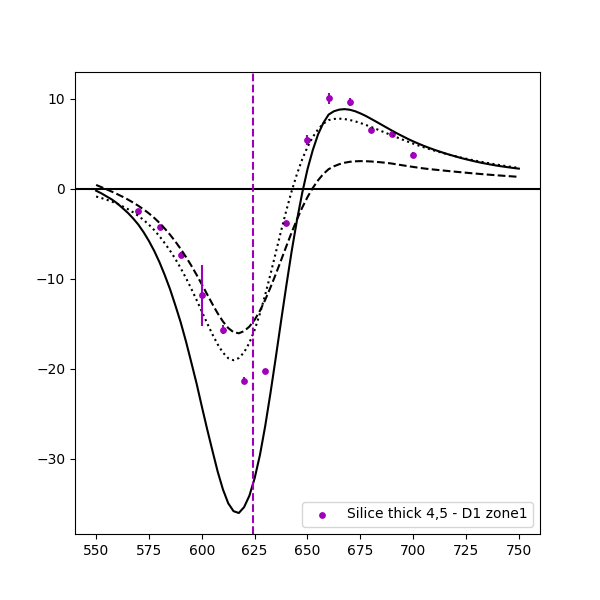

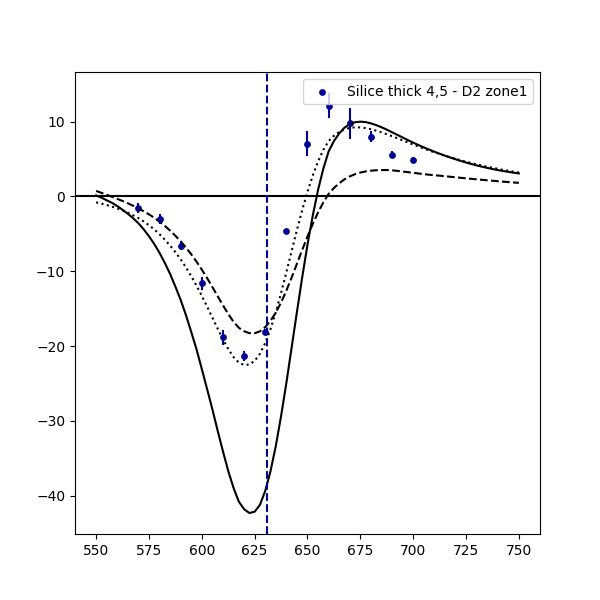

In [11]:
for key in ND_names :
    fig, ax = plt.subplots(figsize = (6, 6))
    ax.plot(Ds[key]['Stoll']['Lambda']*1e9, Ds[key]['Stoll']['tot']*1e18, color="#000000",)
    ax.plot(Ds[key]['Cahill']['Lambda']*1e9, Ds[key]['Cahill']['tot']*1e18, color="#000000",linestyle='--')
    ax.plot(Ds[key]['mine']['Lambda']*1e9, Ds[key]['mine']['tot']*1e18, color="#000000",linestyle='dotted')
    print_thermic_variation_T_norm(ax, Exp_data[key], key)

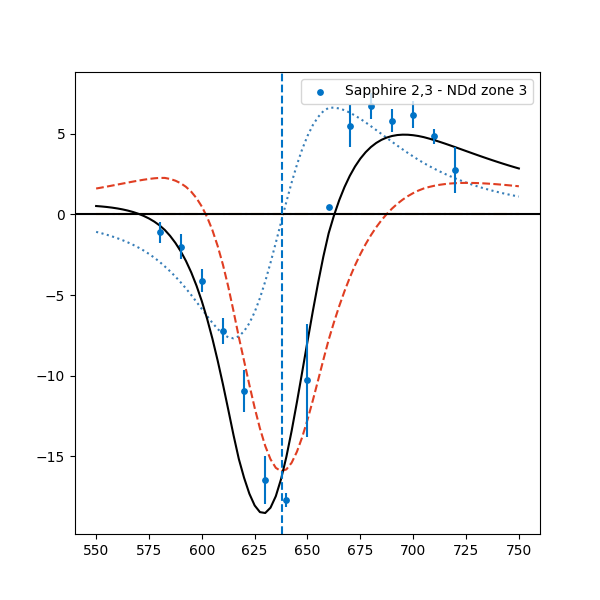

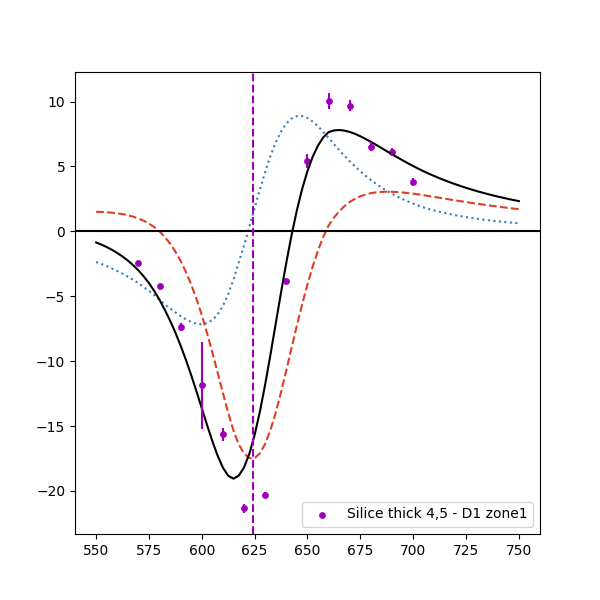

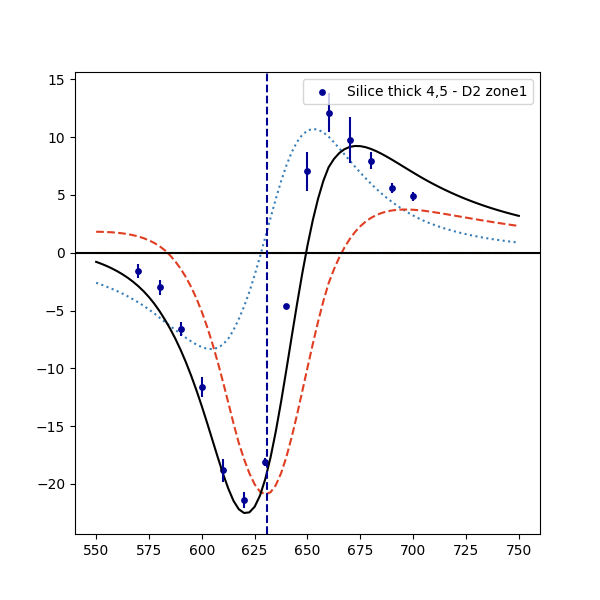

In [12]:
for key in ND_names :
    fig, ax = plt.subplots(figsize = (6, 6))


    ax.plot(Ds[key]['mine']['Lambda']*1e9, Ds[key]['mine']['eps1']*1e18, color='#377Eb8', linestyle='dotted')
    ax.plot(Ds[key]['mine']['Lambda']*1e9, Ds[key]['mine']['eps2']*1e18, color='#E03E22', linestyle='dashed')
    ax.plot(Ds[key]['mine']['Lambda']*1e9, Ds[key]['mine']['geometry']*1e18, color='#ECA208', linestyle='dashdot')
    ax.plot(Ds[key]['mine']['Lambda']*1e9, Ds[key]['mine']['tot']*1e18, color="#000000",)
    print_thermic_variation_T_norm(ax, Exp_data[key], key)

NameError: name 'Ds_Stoll' is not defined

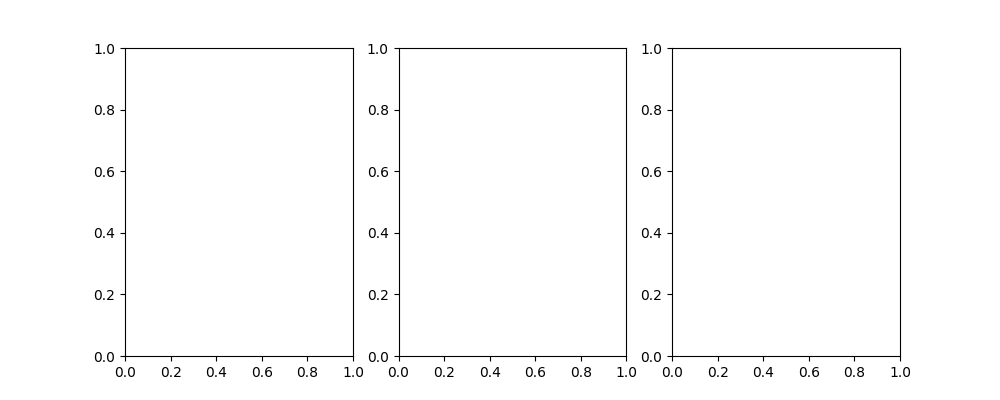

In [13]:
fig, ax = plt.subplots(ncols=3, figsize=(10, 4))

ax[0].plot(Ds_Stoll['Lambda']*1e9, Ds_Stoll['eps1']*1e18, color='#377Eb8', linestyle='dotted')
ax[0].plot(Ds_Stoll['Lambda']*1e9, Ds_Stoll['eps2']*1e18, color='#E03E22', linestyle='dashed')
ax[0].plot(Ds_Stoll['Lambda']*1e9, Ds_Stoll['geometry']*1e18, color='#ECA208', linestyle='dashdot')
ax[0].plot(Ds_Stoll['Lambda']*1e9, Ds_Stoll['tot']*1e18, color="#000000",)
ax[0].set_ylim((-35, 12))


ax[1].plot(Ds_Cahill['Lambda']*1e9, Ds_Cahill['eps1']*1e18, color='#377Eb8', linestyle='dotted')
ax[1].plot(Ds_Cahill['Lambda']*1e9, Ds_Cahill['eps2']*1e18, color='#E03E22', linestyle='dashed')
ax[1].plot(Ds_Cahill['Lambda']*1e9, Ds_Cahill['geometry']*1e18, color='#ECA208', linestyle='dashdot')
ax[1].plot(Ds_Cahill['Lambda']*1e9, Ds_Cahill['tot']*1e18, color="#000000",)
ax[1].set_ylim((-35, 12))



ax[2].plot(Ds_mine['Lambda']*1e9, Ds_mine['eps1']*1e18, color='#377Eb8', linestyle='dotted')
ax[2].plot(Ds_mine['Lambda']*1e9, Ds_mine['eps2']*1e18, color='#E03E22', linestyle='dashed')
ax[2].plot(Ds_mine['Lambda']*1e9, Ds_mine['geometry']*1e18, color='#ECA208', linestyle='dashdot')
ax[2].plot(Ds_mine['Lambda']*1e9, Ds_mine['tot']*1e18, color="#000000",)
ax[2].set_ylim((-35, 12))